In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import random
from scipy.spatial.distance import cdist
from sklearn.metrics import pairwise_distances
from scipy.stats import kstest
import seaborn as sns
import matplotlib.pyplot as plt
import sys

sys.path.append("../mapqc_design_label_independent")
import pval_corr

In [2]:
print('test')

test


In [3]:
%load_ext lab_black

In [4]:
path_hlca_ext = "../../data/HLCA_full_v1.1_emb.h5ad"

In [5]:
adata_full = sc.read_h5ad(path_hlca_ext)

Set parameters for metric:

In [6]:
n_nhoods = 100
k = 1000
min_n_cells_per_sample_per_nhood = 5
min_n_samples_per_nhood_r_or_q = 3
use_mean_dist_to_all_ref_samples = True

HELPER FUNCTIONS for separate python script:

In [7]:
def get_column_numbers_of_lowest_values(distances: np.array, n: int):
    """
    Computes the indices of the lowest values in a distance matrix,
    row-wise.

    Parameters
    ----------
    distances
        Array of size m x p with euclidean distances between observations  1...m
        and observations 1 ... p
    n
        The lowest n values to extract the column indices for.

    Returns
    -------
    Array of size (m, n) of lowest value indices for observations 1...m.
    """
    # get indices of columns sorted from small to large
    sorted_indices = np.argsort(distances, axis=1)
    # get column numbers for the columns with the n lowest values
    lowest_value_column_idc = sorted_indices[:, :n]
    return lowest_value_column_idc

In [ ]:
# temp = sc.read_h5ad(
#     "/lustre/groups/ml01/workspace/hlca_lisa.sikkema_malte.luecken/HLCA_reproducibility/data/HLCA_extended/extension_datasets/ready/subsetted/lambrechts_sub.h5ad"
# )

In [ ]:
# lambrechts_sample_info = temp.obs.groupby("sample").agg(
#     {"tumor_site": "first", "cell_from_tumor": "first"}
# )

list reference datasets:

In [8]:
print("Reference datasets:")
print(
    sorted(
        adata_full.obs.loc[
            adata_full.obs.core_or_extension == "core", "dataset"
        ].unique()
    )
)

Reference datasets:
['Banovich_Kropski_2020', 'Barbry_Leroy_2020', 'Jain_Misharin_2021_10Xv1', 'Jain_Misharin_2021_10Xv2', 'Krasnow_2020', 'Lafyatis_Rojas_2019_10Xv1', 'Lafyatis_Rojas_2019_10Xv2', 'Meyer_2019', 'Misharin_2021', 'Misharin_Budinger_2018', 'Nawijn_2021', 'Seibold_2020_10Xv2', 'Seibold_2020_10Xv3', 'Teichmann_Meyer_2019']


list query datasets:

In [9]:
print("Query datasets:")
print(
    sorted(
        adata_full.obs.loc[
            adata_full.obs.core_or_extension == "extension", "dataset"
        ].unique()
    )
)

Query datasets:
['Banovich_Kropski_2020', 'Budinger_2020', 'Duong_lungMAP_unpubl', 'Eils_2020', 'Gomperts2021_UCLA', 'Gomperts_2021_CFF', 'Gomperts_2021_CSMC', 'Janssen_2020', 'Kaminski_2020', 'Lafyatis_2019', 'Lambrechts_2021', 'MeyerNikolic_unpubl_UCL', 'Meyer_2021_3prime', 'Meyer_2021_5prime', 'Misharin_Budinger_2018', 'Peer_Massague_2020', 'Regev_2021_Cryo', 'Regev_2021_Fresh', 'Regev_2021_Nuclei', 'Schiller_2020', 'Schiller_2021', 'Schultze_unpubl', 'Shalek_2018', 'Sheppard_2020', 'Sims_2019', 'Sun_2020_batch1', 'Sun_2020_batch2', 'Sun_2020_batch3', 'Sun_2020_batch4', 'Tata_unpubl', 'Thienpont_2018_10Xv1', 'Thienpont_2018_10Xv2', 'Wunderink_2021_cryo', 'Wunderink_2021_fresh', 'Xu_2020_LAM1_3', 'Zhang_2021']


subset to query dataset of choice:

In [10]:
query_dataset = "Zhang_2021"

In [11]:
adata = adata_full[
    (adata_full.obs.core_or_extension == "core")
    | (adata_full.obs.dataset == query_dataset)
].copy()

In [12]:
if query_dataset in (
    adata.obs.loc[adata.obs.core_or_extension == "core", "dataset"].values
):
    print(f"Setting dataset {query_dataset} to 'query' as query simulation.")
    adata.obs.core_or_extension = adata.obs.core_or_extension.tolist()
    adata.obs.loc[adata.obs.dataset == query_dataset, "core_or_extension"] = "extension"

In [13]:
if query_dataset in ["Thienpont_2018_10Xv1", "Thienpont_2018_10Xv2"]:
    print("setting Thienpont tumor adjacent samples to 'Healthy'")
    lambrechts_sample_info = pd.read_csv(
        "./lambrechts_health_status_info.csv", index_col=0
    )
    lambrechts_healthy_samples = lambrechts_sample_info.loc[
        ~lambrechts_sample_info.cell_from_tumor, :
    ].index.tolist()
    adata.obs.loc[
        adata.obs["sample"].values.isin(lambrechts_healthy_samples), "lung_condition"
    ] = "Healthy"

check which health conditions are in the query:

In [14]:
sorted(adata.obs.loc[adata.obs.dataset == query_dataset, "lung_condition"].unique())

['COVID-19 moderate', 'COVID-19 severe', 'Healthy']

If wanted, subset to specific condition for the query specifically (reference is already fully healthy):

In [15]:
adata = adata[
    (adata.obs.core_or_extension == "core") | (adata.obs.lung_condition == "Healthy")
].copy()

In [44]:
query_cell_idc = np.where(adata.obs.core_or_extension == "extension")[0].tolist()
random.seed(0)
center_cell_idc = random.sample(query_cell_idc, k=n_nhoods)
center_cells = np.array(adata.obs.iloc[center_cell_idc, :].index)

calculate distance to all cells for index cells (more efficient than running standard knn graph)

In [45]:
dist_to_center_cells = cdist(
    adata[center_cells].X, adata.X
)  # (n_nhoods x n_total_cells)

get k nearest neighbors (their indices) for each center cell 

In [46]:
nn_of_center_cells = get_column_numbers_of_lowest_values(
    dist_to_center_cells, k
)  # (n_nhoods x k)

In [47]:
nn_of_center_cells.shape

(100, 1000)

create empty 3D tensor to store results in, of shape (n_ref_samples x n_samples x n_nhoods)

In [48]:
ref_samples = np.array(
    sorted(adata.obs.loc[adata.obs.core_or_extension == "core", "sample"].unique())
)
all_samples = np.concatenate(
    (
        ref_samples,
        np.array(
            sorted(
                adata.obs.loc[
                    adata.obs.core_or_extension == "extension", "sample"
                ].unique()
            )
        ),
    )
)
mean_s2s_dist_per_nhood = np.empty(
    (len(ref_samples), len(all_samples), len(center_cells))
)
mean_s2s_dist_per_nhood[:] = np.nan

Now calculate pairwise mean distances from ref samples to all samples for each neighborhood:

In [49]:
# loop through neighborhoods (their count, index in the original anndata,
# and barcode/name):
for center_cell_count, (center_idx_i, center_cell_i) in enumerate(
    zip(center_cell_idc, center_cells)
):
    # extract the cells (barcodes) in this neighborhood (i.e. k nearest neighbors
    # of center cell, including itself)
    nn = adata.obs.index[nn_of_center_cells[center_cell_count]]
    # ..the embedding coordinates of the cells
    nn_emb_coord = adata[nn, :].X  # k x n_latent_dims
    # ..the sample each cell belongs to
    nn_samples = adata.obs.loc[nn, "sample"].values  # k
    # ..whether the cells are part of the reference or the query:
    nn_r_vs_q = adata.obs.loc[nn, "core_or_extension"].values  # k
    # now calculate the pairwise distances between all k cells
    nn_dists = pairwise_distances(nn_emb_coord)  # k x k
    # Filter samples, ref first: check which reference samples have at least
    # min_n_cells_per_sample_per_nhood cells in the nhood
    ref_sample_cell_counts_nhood = nn_samples[nn_r_vs_q == "core"].value_counts()
    ref_samples_nhood = ref_sample_cell_counts_nhood.index[
        ref_sample_cell_counts_nhood >= min_n_cells_per_sample_per_nhood
    ].tolist()  # <=k
    n_ref_samples_nhood = len(ref_samples_nhood)
    # check the same for the query samples:
    q_sample_cell_counts_nhood = nn_samples[nn_r_vs_q == "extension"].value_counts()
    q_samples_nhood = q_sample_cell_counts_nhood.index[
        q_sample_cell_counts_nhood >= min_n_cells_per_sample_per_nhood
    ].tolist()  # <=k
    n_q_samples_nhood = len(q_samples_nhood)
    # if either ref or query do not have enough samples, skip this nhood:
    if (
        n_ref_samples_nhood < min_n_samples_per_nhood_r_or_q
        or n_q_samples_nhood < min_n_samples_per_nhood_r_or_q
    ):
        # no reference cells sampled, skip neighborhood
        continue
    # create empty dataframe for neighborhood results. It will have the
    # distances between sample pairs, calculated as the average over all
    # cell pairs from those two samples. For now, we only calculate distances
    # to reference samples, so it will be of shape:
    # (n_ref_samples x (n_ref_samples + n_q_samples))
    res_nhood = pd.DataFrame(
        index=ref_samples_nhood, columns=ref_samples_nhood + q_samples_nhood
    )
    # loop through all reference samples to calculate their mean distance to
    # all other samples
    for r_sample_n, r_sample in enumerate(ref_samples_nhood):
        # get indices of cells in the neighborhood from this reference sample
        nn_cell_idc_from_r_sample = np.where(nn_samples == r_sample)[0]
        # loop through all ref + query samples that we haven't already
        # looped through in the first for loop (in this way we avoid
        # calculating the same value twice, and under-estimating our variance
        # later on)
        for sample_2 in (ref_samples_nhood + q_samples_nhood)[r_sample_n + 1 :]:
            # get indices of cells in the neighborhood from this second sample
            nn_cell_idc_from_sample_2 = np.where(nn_samples == sample_2)[0]
            # subset nhood's distance matrix to cells from the two samples
            dists_between_samples_cells = nn_dists[nn_cell_idc_from_r_sample][
                :, nn_cell_idc_from_sample_2
            ]
            # check overall index of two samples we are calculating distance
            # between. This will enable us to store the results in our
            # tensor:
            r_sample_idx = np.where(r_sample == ref_samples)[0]
            sample_2_idx = np.where(sample_2 == all_samples)[0]
            # calculate mean distance between all cell pairs
            # Q: should we condider median here? shouldn't matter so much,
            # as we already selected cells from a neighborhood so no extreme
            # outliers expected...
            ss_mean_pairwise_distance = np.mean(dists_between_samples_cells)
            res_nhood.loc[r_sample, sample_2] = ss_mean_pairwise_distance
            mean_s2s_dist_per_nhood[
                r_sample_idx, sample_2_idx, center_cell_count
            ] = ss_mean_pairwise_distance
            # if we plan to use mean pairwise distance for a given sample to
            # all reference samples, let's fill out the entire tensor (so i,j
            # as well as j,i) even though they are the same, so that we can
            # get the mean for each sample across *all* reference samples later
            # on.
            if use_mean_dist_to_all_ref_samples and sample_2 in ref_samples_nhood:
                mean_s2s_dist_per_nhood[
                    sample_2_idx, r_sample_idx, center_cell_count
                ] = ss_mean_pairwise_distance

In [50]:
nn

Index(['GAACCTAAGATGCCAG_1_liao', 'CGCGGTAAGACGCACA_1_liao',
       'GTCCTCAAGATCACGG_1_liao', 'GGGCATCCACCGTTGG_1_liao',
       'GCAGCCACAAAGAATC_1_liao', 'AGCGTCGAGATACACA_1_liao',
       'GCTTCACAGCTAGTTC_3_liao', 'AAGTCTGCATTAGCCA_1_liao',
       'ATGAGGGCATGTAGTC_1_liao', 'CTTAGGAGTTGTCGCG_1_liao',
       ...
       'TTGGAACCACCAACCG_1_liao', 'CTCGAGGGTATCAGTC_1_liao',
       'GCATGATTCTCAACTT_1_liao', 'TGAGAGGAGCGACGTA_2_liao',
       'GTACTCCGTTCATGGT_1_liao', 'CACAGGCAGCCAACAG_2_liao',
       'GAGTCCGGTTCCACGG_2_liao', 'GTTCTCGGTGTAACGG_1_liao',
       'TACTTGTTCCTCATTA_1_liao', 'GATGAGGCAATGGAGC_1_liao'],
      dtype='object', length=1000)

convert results to dataframe for plotting:

In [51]:
if use_mean_dist_to_all_ref_samples:
    # take mean distance across all reference samples for each sample, in each
    # neighborhood
    mean_s_dist_to_refsamples_per_nhood = np.nanmean(mean_s2s_dist_per_nhood, axis=0)
    # convert to pandas dataframe
    mean_s2ref_dist_per_nhood_df_for_boxplot = (
        pd.DataFrame(
            mean_s_dist_to_refsamples_per_nhood, index=all_samples, columns=center_cells
        )
        .unstack()
        .reset_index()
        .rename(
            columns={"level_0": "nhood", "level_1": "sample", 0: "mean_dist_to_ref"}
        )
    )
    # remove rows with nans
    mean_s2ref_dist_per_nhood_df_for_boxplot.dropna(how="any", axis=0, inplace=True)
    # add info on whether sample is from ref or query
    sample_from_r_or_q_df = adata.obs.groupby("sample").agg(
        {"core_or_extension": "first"}
    )
    sample_from_r_or_q_dict = {
        s: rvsq
        for s, rvsq in zip(
            sample_from_r_or_q_df.index, sample_from_r_or_q_df.core_or_extension
        )
    }
    mean_s2ref_dist_per_nhood_df_for_boxplot[
        "sample_r_or_q"
    ] = mean_s2ref_dist_per_nhood_df_for_boxplot["sample"].map(sample_from_r_or_q_dict)

/tmp/ipykernel_1359916/3036149507.py:4: RuntimeWarning: Mean of empty slice
  mean_s_dist_to_refsamples_per_nhood = np.nanmean(mean_s2s_dist_per_nhood, axis=0)


In [52]:
if not use_mean_dist_to_all_ref_samples:
    # create empty dataframe for storing the relevant info:
    mean_s2s_dist_per_nhood_df_for_boxplot = pd.DataFrame(
        columns=["nhood", "sample_r", "sample_2", "sample_2_r_or_q", "mean_dist"]
    )
    # now fill in dataframe, neighborhood by neighborhood:
    for nhood_number, nhood in enumerate(center_cells):
        # get results for given neighborhood
        center_cell_res = mean_s2s_dist_per_nhood[:, :, nhood_number]
        # convert to dataframe, remove rows + columns with only nas (i.e. samples
        # that were not present in the neighborhood or did not pass filtering)
        center_cell_res_df_stacked = (
            pd.DataFrame(center_cell_res, index=ref_samples, columns=all_samples)
            .dropna(axis=0, how="all")
            .dropna(axis=1, how="all")
        )
        # move multi-index indices to columns and rename columns
        center_cell_res_df = (
            center_cell_res_df_stacked.unstack()
            .reset_index()
            .rename(
                columns={"level_0": "sample_2", "level_1": "sample_r", 0: "mean_dist"}
            )
        )
        # drop rows that have no distance calculated (these are rows for which
        # we already have the reverse distance, i.e. ref_sample_1 to ref_sample_2,
        # we'll leave out the reverse result as it is the same thing)
        center_cell_res_df = center_cell_res_df.loc[
            ~center_cell_res_df.mean_dist.isna(), :
        ]
        # add neighborhood information, and info on where the second sample came
        # from (ref or query)
        center_cell_res_df["nhood"] = nhood
        center_cell_res_df["sample_2_r_or_q"] = "query"
        center_cell_res_df.loc[
            center_cell_res_df.sample_2.isin(ref_samples), "sample_2_r_or_q"
        ] = "reference"
        # now concatenate nhood results to overall results dataframe
        mean_s2s_dist_per_nhood_df_for_boxplot = pd.concat(
            (mean_s2s_dist_per_nhood_df_for_boxplot, center_cell_res_df),
            axis=0,
            ignore_index=True,
        )

calculate stats:

In [53]:
use_mean_dist_to_all_ref_samples

True

In [54]:
nhood_stats = pd.DataFrame(index=center_cells, columns=["ks_stat", "pval"])

In [55]:
mean_s_dist_to_refsamples_per_nhood.shape

(169, 100)

In [56]:
for nhood_number, nhood in enumerate(center_cells):
    if not use_mean_dist_to_all_ref_samples:
        nhood_res = mean_s2s_dist_per_nhood[:, :, nhood_number]
        if np.isnan(nhood_res).all():
            continue
        # extract distances between ref-ref sample pairs, flatten to 1D array
        r2r_dists = nhood_res[:, : len(ref_samples)].flatten()
        # do the same for ref-query sample pairs
        r2q_dists = nhood_res[:, len(ref_samples) :].flatten()
    elif use_mean_dist_to_all_ref_samples:
        r2r_dists = mean_s_dist_to_refsamples_per_nhood[
            : len(ref_samples), nhood_number
        ]
        r2q_dists = mean_s_dist_to_refsamples_per_nhood[
            len(ref_samples) :, nhood_number
        ]
        if np.isnan(r2r_dists).all() or np.isnan(r2q_dists).all():
            continue
    # remove nans
    r2r_dists = r2r_dists[~np.isnan(r2r_dists)]
    r2q_dists = r2q_dists[~np.isnan(r2q_dists)]
    # perform KS test
    nhood_stats.loc[nhood] = kstest(
        rvs=r2r_dists, cdf=r2q_dists, alternative="greater"
    )[:2]

keep only nhoods that passed filtering:

In [57]:
nhood_stats["nhood_number"] = range(0, len(center_cells))
nhood_stats.dropna(axis=0, how="any", inplace=True)

In [58]:
perc_of_nhoods_passed_filter = round(nhood_stats.shape[0] / n_nhoods * 100)
print(f"{perc_of_nhoods_passed_filter}% of neighborhoods passed filtering.")

14% of neighborhoods passed filtering.


In [59]:
nn_of_center_cells[nhood_stats.nhood_number, :]

array([[436659,  37137, 364879, ..., 427229, 159780,  46518],
       [226888, 123501, 587727, ..., 526003, 248287, 382467],
       [104342, 566571,  48762, ..., 378883, 420851, 135988],
       ...,
       [559412,  17572, 335293, ..., 544835, 491497, 136787],
       [283898, 444586, 234502, ..., 143970, 471647,  25399],
       [283549, 372581, 471660, ..., 574454, 125575, 524955]])

In [60]:
nn_of_center_cells[nhood_stats.nhood_number, :].shape

(14, 1000)

In [61]:
nhood_stats["nhood_weight"] = pval_corr.calculate_neighborhood_weights(
    nn_of_center_cells[nhood_stats.nhood_number, :], adata.n_obs
)

In [62]:
nhood_stats["pval_corr"] = pval_corr.weighted_fdr_corr_pvals(
    nhood_stats.pval, nhood_stats.nhood_weight
)

In [63]:
nhood_stats["sign"] = nhood_stats.pval_corr < 0.05

In [64]:
nhood_stats.head(10)

,ks_stat,pval,nhood_number,nhood_weight,pval_corr,sign
ATCACAGCAGTGTGGA_3_liao,0.9,0.013986,1,0.499525,0.019815,True
ATTTCTGTCGCATTAG_3_liao,1.0,0.001032,11,0.566252,0.010608,True
GTACAGTGTATTGACC_3_liao,1.0,0.001786,21,0.733396,0.010608,True
CAGCATAGTTAAGACA_1_liao,1.0,0.017857,24,0.691893,0.019815,True
TCCGAAACACTGCGTG_3_liao,1.0,0.017857,33,0.394228,0.019815,True
TGAATGCCACTGGATT_3_liao,1.0,0.011905,40,0.619480,0.019085,True
GCTGCTTGTACCGCTG_1_liao,1.0,0.008333,50,0.739569,0.017979,True
TTCCAATGTACTGGGA_3_liao,0.923077,0.007143,64,0.600824,0.017979,True
AAGGTAAGTACCAGAG_3_liao,1.0,0.006061,65,0.371894,0.017979,True
TGTATTCCAGTCAGCC_2_liao,1.0,0.011905,73,0.722283,0.019085,True


Plot boxplot:

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_basic/lib/python3.9/site-packages/seaborn/categorical.py:166: FutureWarning: Setting a gradient palette using color= is deprecated and will be removed in version 0.13. Set `palette='dark:black'` for same effect.
  warnings.warn(msg, FutureWarning)


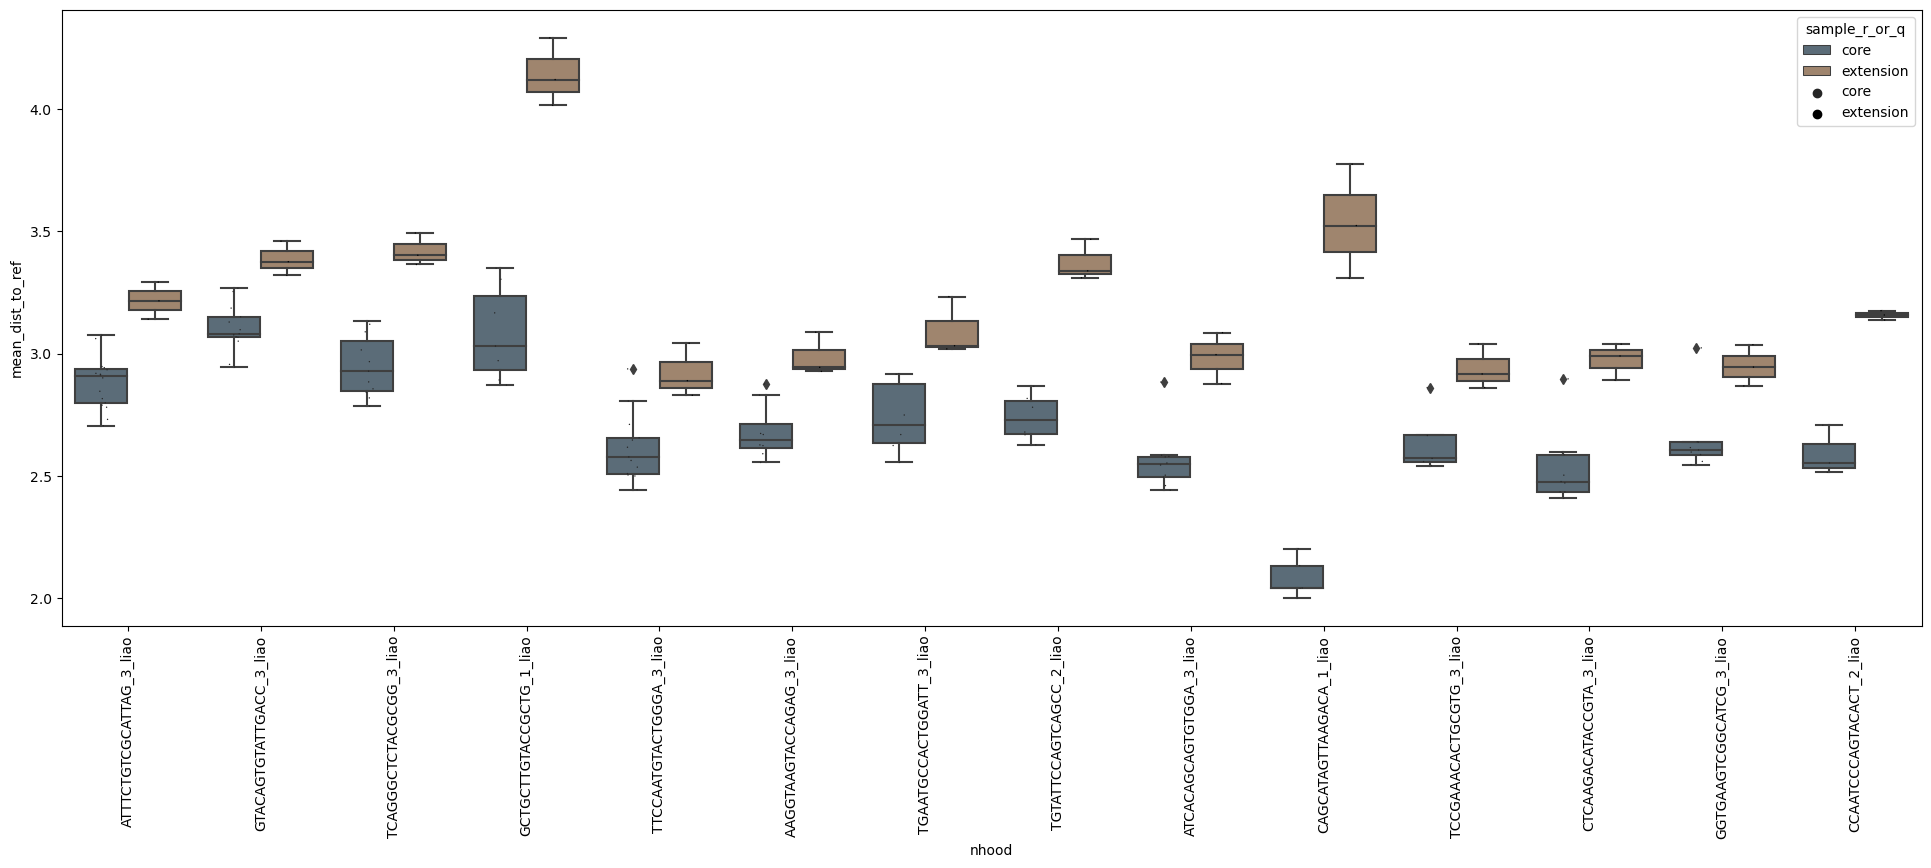

In [65]:
fig = plt.figure(figsize=(24, 8))
ax = fig.add_subplot()
nhood_order = nhood_stats.sort_values(by="pval_corr").index.tolist()
if use_mean_dist_to_all_ref_samples:
    df_for_boxplot = mean_s2ref_dist_per_nhood_df_for_boxplot
    y = "mean_dist_to_ref"
    hue = "sample_r_or_q"
else:
    df_for_boxplot = mean_s2s_dist_per_nhood_df_for_boxplot
    y = "mean_dist"
    hue = "sample_2_r_or_q"
sns.boxplot(
    df_for_boxplot,
    x="nhood",
    y=y,
    order=nhood_order,
    hue=hue,
    ax=ax,
    saturation=0.2,
)
sns.stripplot(
    df_for_boxplot,
    x="nhood",
    y=y,
    order=nhood_order,
    hue=hue,
    dodge=True,
    ax=ax,
    size=1,
    color="black",
)
ax.tick_params(axis="x", rotation=90)

### Add stats to anndata and plot umaps:

In [66]:
for stat_to_copy in ["nhood_weight", "pval_corr", "sign"]:
    adata.obs[stat_to_copy] = np.nan
    adata.obs.loc[nhood_stats.index, stat_to_copy] = nhood_stats[stat_to_copy]
# set sizes for plotting:
scale = 1
adata.obs["dotsize"] = scale * 1
adata.obs.loc[nhood_stats.index, "dotsize"] = scale * 20

order adata such that index cells are on top:

In [67]:
cells_ordered = (
    adata.obs.index[~adata.obs.index.isin(nhood_stats.index)].tolist()
    + nhood_stats.index.tolist()
)

In [68]:
adata = adata[cells_ordered, :].copy()

In [69]:
sc.set_figure_params(figsize=(5, 5))

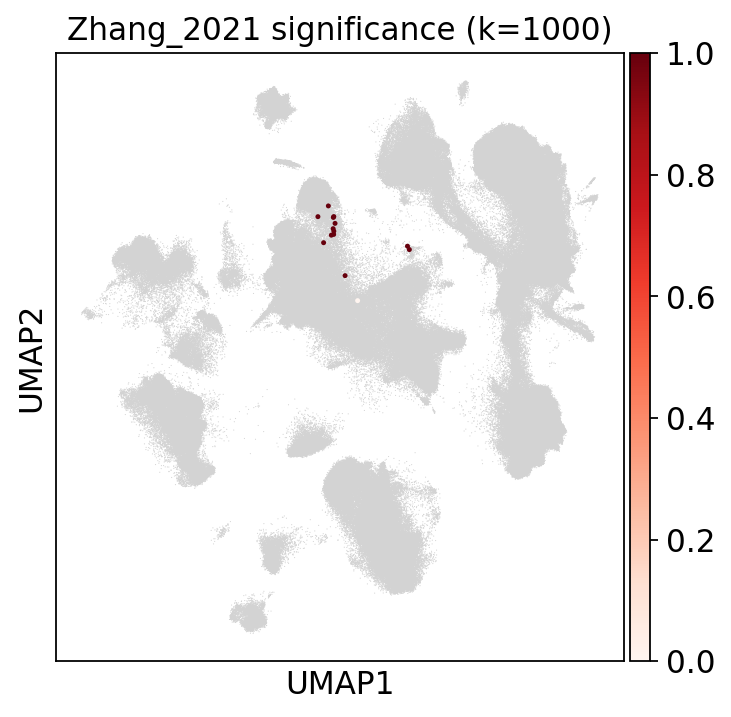

In [70]:
sc.pl.umap(
    adata,
    color="sign",
    size=adata.obs.dotsize,
    cmap="Reds",
    sort_order=False,
    title=f"{query_dataset} significance (k={k})",
    vmin=0,
    vmax=1,
)

In [71]:
print(
    "n samples:", adata.obs.loc[adata.obs.dataset == query_dataset, "sample"].nunique()
)
print(
    round(nhood_stats.sign.sum() / nhood_stats.shape[0] * 100),
    "% of neighborhoods significant",
)

n samples: 3
93 % of neighborhoods significant


/home/icb/lisa.sikkema/miniconda3/envs/mapqc_basic/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_basic/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


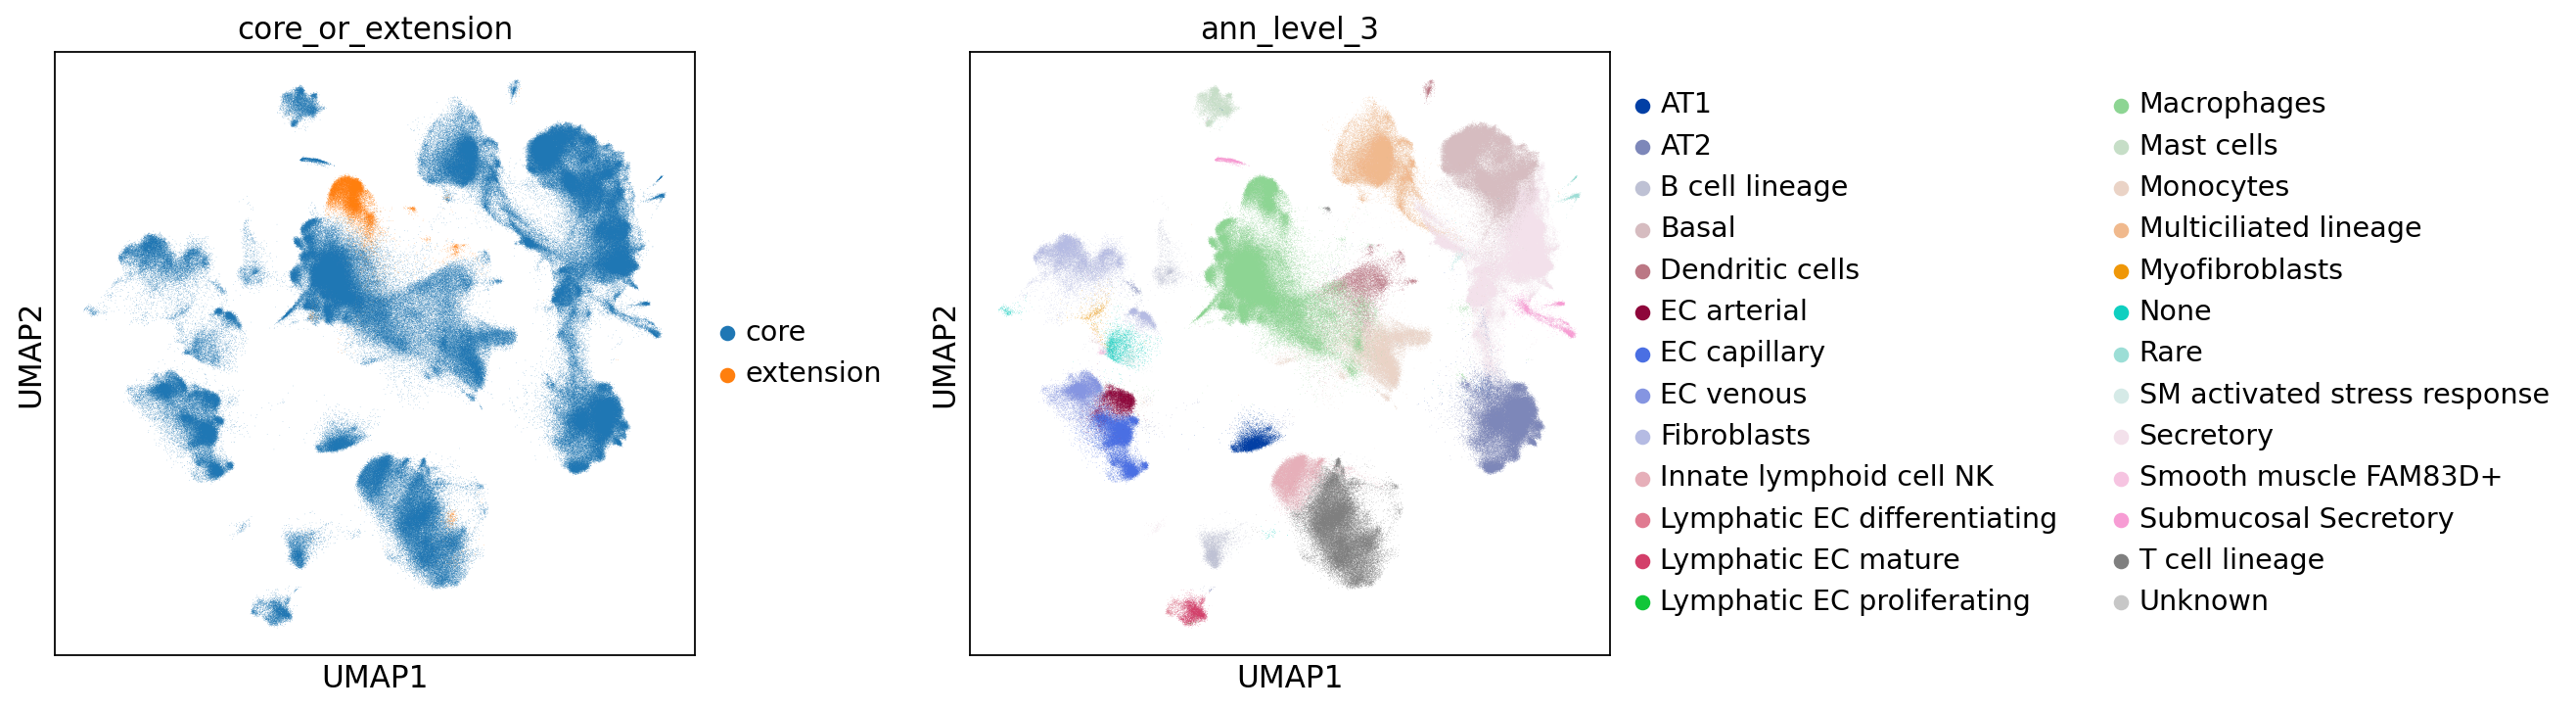

In [72]:
sc.pl.umap(adata, color=["core_or_extension", "ann_level_3"], wspace=0.3)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_basic/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


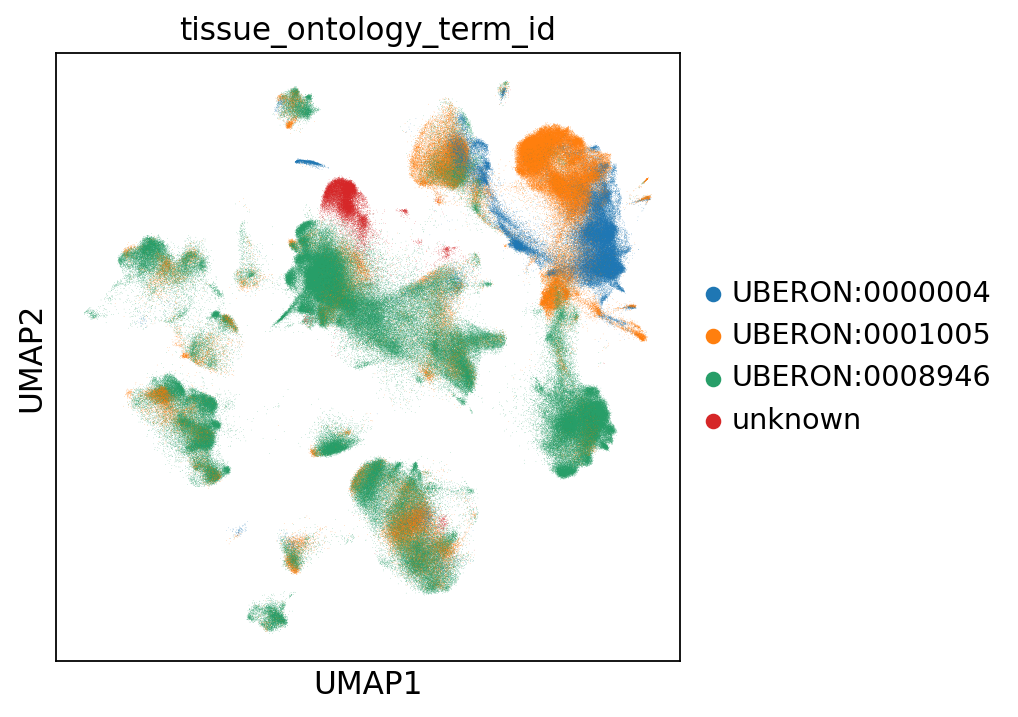

In [73]:
sc.pl.umap(adata, color=["tissue_ontology_term_id"], wspace=0.3)

In [74]:
adata_full.obs.loc[adata_full.obs.dataset == "Thienpont_2018_10Xv1", "sample"].unique()

['BT1248', 'BT1244', 'BT1241', 'BT1239', 'BT1242', ..., 'BT1238', 'BT1249', 'BT1243', 'BT1240', 'BT1245']
Length: 12
Categories (731, object): ['001C', '002C', '003C', '010I', ..., 'scrBT1429', 'scrBT1430', 'scrBT1431', 'scrBT1432']